# 03 - Portfolio optimisation: the ten models

**Research purpose.** Implement each construction rule on one estimation window, inspect its weights and ex-ante properties,
and understand what *inputs* each one depends on. No performance claims are made here - weights computed on a single window say nothing about out-of-sample quality.

| Model | Inputs | Constraint |
|---|---|---|
| equal_weight | none | - |
| gmv_long_only | $\Sigma$ | $w\ge0$ |
| mean_variance | $\mu,\Sigma$ | $w\ge0$, target return |
| max_sharpe | $\mu,\Sigma$ | $w\ge0$ |
| min_vol_capped | $\Sigma$ | $0\le w\le25\%$ |
| ledoit_wolf_minvar | LW $\Sigma$ | $w\ge0$ |
| robust_mv | $\mu,\Sigma$ + uncertainty set | $w\ge0$ |
| risk_parity | $\Sigma$ | $w>0$ |
| black_litterman | prior + views, $\Sigma$ | $w\ge0$ |
| cond_vol_minvar | EWMA $\Sigma$ | $w\ge0$ |

In [8]:
import sys, warnings
import os
from pathlib import Path
try:  
    os.chdir(Path(__vsc_ipynb_file__).resolve().parent)
except NameError:  
    pass
sys.path.insert(0, os.path.abspath(".."))
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from src import data_processing as dp, covariance_estimators as ce, portfolio_models as pm
from src import stability_tests as st, regime_detection as rd, stress_testing as sx, evaluation as ev
plt.rcParams["figure.dpi"] = 110


_candidates = ["returns_simple_daily.csv", "returns_daily.csv"]
_path = next((Path("../data/processed") / f for f in _candidates if (Path("../data/processed") / f).exists()), None)
if _path is None:
    raise FileNotFoundError("Run notebook 01 first: expected ../data/processed/returns_simple_daily.csv")
returns = pd.read_csv(_path, index_col=0, parse_dates=True)
print("loaded:", _path.name)
X = returns.to_numpy()
print(returns.shape, returns.index[0].date(), "->", returns.index[-1].date())

loaded: returns_simple_daily.csv
(3519, 5) 2012-01-04 -> 2025-12-31


## 1. Weights on the latest 504-day window

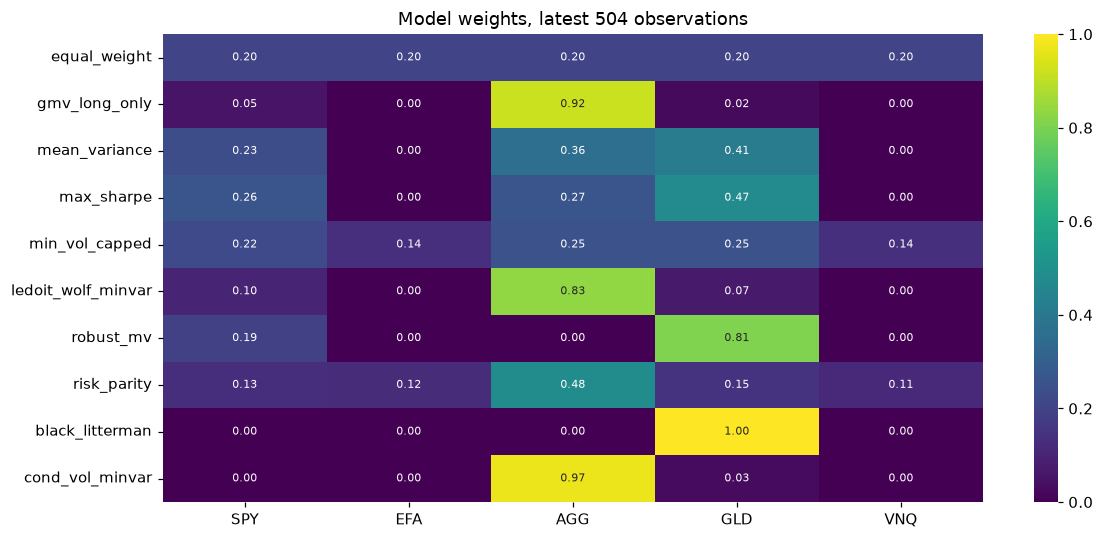

In [9]:
window = X[-504:]
W = pd.DataFrame({m: pm.MODELS[m](window) for m in pm.CORE_TEN}, index=returns.columns)
fig, ax = plt.subplots(figsize=(11, 5))
sns.heatmap(W.T, annot=True, fmt=".2f", cmap="viridis", ax=ax, annot_kws={"size": 7})
ax.set_title("Model weights, latest 504 observations")
plt.tight_layout()
output_path = Path(r"C:\Users\user\Desktop\portfolio-structural-validity\results\figures\model_weights_latest_504.png")
output_path.parent.mkdir(parents=True, exist_ok=True)
fig.savefig(output_path, dpi=150, bbox_inches="tight")

**Interpret:** which models concentrate? Count the zero (or near-zero) weights in the long-only optimisers. Why does a long-only optimiser put exactly zero weight on many assets (think KKT complementary slackness)?

**Interpretation:** Most long-only optimizers concentrated their allocations in only a few ETFs, often assigning zero or nearly zero weight to others. GMV, Ledoit–Wolf, and conditional-volatility minimum variance favored AGG; robust mean-variance and Black–Litterman heavily favored GLD. By contrast, the capped minimum-volatility and risk-parity models held all five assets. These zero weights occur when the optimizer’s nonnegativity constraint is active: under KKT complementary slackness, an asset at its lower bound can be excluded if including it would not improve the objective. This snapshot reflects one 504-day estimation window, so the chosen weights may change over time.

In [10]:
S = ce.sample_covariance(window); mu = ce.sample_mean(window)
rows = {m: {**pm.portfolio_stats(W[m].values, mu, S),
            "effective_N": ev.effective_n(W[m].values),
            "n_assets_>1%": int((W[m] > 0.01).sum())} for m in W}
result = pd.DataFrame(rows).T.round(3)
from pathlib import Path
output_path = Path(r"C:\Users\user\Desktop\portfolio-structural-validity\results\tables\latest_504_model_statistics.csv")
output_path.parent.mkdir(parents=True, exist_ok=True)
result.to_csv(output_path)
result

,exp_return,volatility,sharpe,effective_N,n_assets_>1%
equal_weight,0.167,0.101,1.655,5.000,5.0
gmv_long_only,0.057,0.049,1.167,1.172,3.0
mean_variance,0.217,0.091,2.394,2.853,3.0
max_sharpe,0.243,0.101,2.399,2.751,3.0
min_vol_capped,0.180,0.095,1.894,4.688,5.0
ledoit_wolf_minvar,0.079,0.050,1.573,1.411,3.0
robust_mv,0.343,0.148,2.314,1.455,2.0
risk_parity,0.128,0.074,1.730,3.328,5.0
black_litterman,0.377,0.176,2.143,1.000,1.0
cond_vol_minvar,0.050,0.050,0.997,1.058,2.0


**Warning to interpret correctly:** the `exp_return` and `sharpe` columns are *in-sample, ex-ante*. A model that targets the sample mean will mechanically show the highest value here. Notebook 08 compares them with realised out-of-sample numbers.

## 2. Risk contributions

,equal_weight,gmv_long_only,mean_variance,max_sharpe,min_vol_capped,ledoit_wolf_minvar,robust_mv,risk_parity,black_litterman,cond_vol_minvar
SPY,0.251,0.054,0.219,0.219,0.289,0.144,0.067,0.2,0.0,0.000
EFA,0.253,0.000,0.000,0.000,0.175,0.000,0.000,0.2,0.0,0.000
AGG,0.043,0.922,0.078,0.044,0.058,0.757,0.000,0.2,0.0,0.972
GLD,0.193,0.024,0.703,0.737,0.297,0.099,0.933,0.2,1.0,0.028
VNQ,0.261,0.000,0.000,0.000,0.180,0.000,0.000,0.2,0.0,0.000


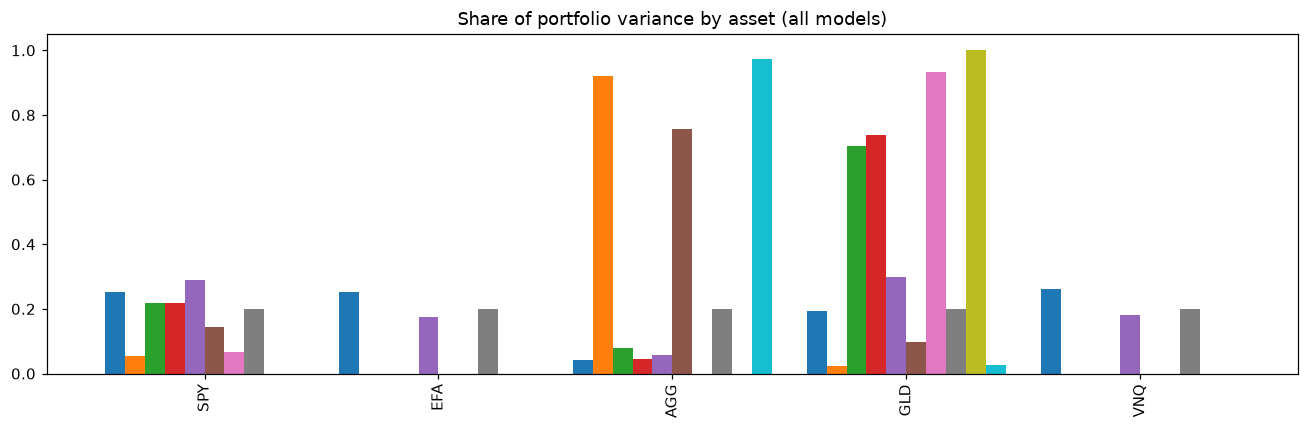

In [11]:
rc = pd.DataFrame({m: pm.risk_contributions(W[m].values, S) for m in W}, index=returns.columns)
rc.plot(kind="bar", figsize=(12, 4), width=0.85, legend=False)
plt.title("Share of portfolio variance by asset (all models)")
plt.tight_layout()
output_path = Path(r"C:\Users\user\Desktop\portfolio-structural-validity\results\figures\risk_contributions_all_models.png")
output_path.parent.mkdir(parents=True, exist_ok=True)
plt.savefig(output_path, dpi=150, bbox_inches="tight")
result = rc.round(3)
table_path = Path(r"C:\Users\user\Desktop\portfolio-structural-validity\results\tables\risk_contributions_all_models.csv")
table_path.parent.mkdir(parents=True, exist_ok=True)
result.to_csv(table_path)
result

**Check:** `risk_parity` should show roughly equal bars. Why can *equal weights* still be extremely concentrated in risk terms?

## 3. Efficient frontier (long-only) and where the models sit

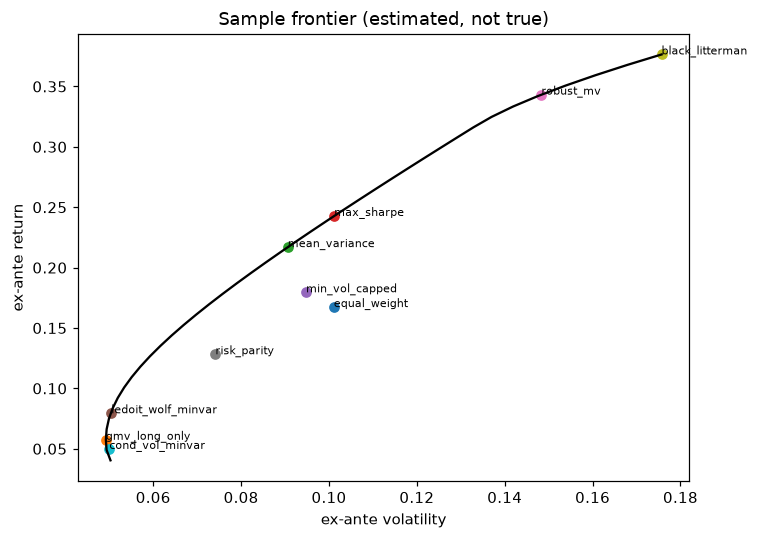

In [12]:
targets = np.linspace(mu.min(), mu.max(), 40)
vol, ret = [], []
for t in targets:
    try:
        w = pm.mean_variance_target(window, target=float(t))
        vol.append(np.sqrt(w @ S @ w * 252)); ret.append(w @ mu * 252)
    except Exception:
        pass
fig, ax = plt.subplots(figsize=(7, 5))
ax.plot(vol, ret, "k-", label="sample long-only frontier")
for m in W:
    s = pm.portfolio_stats(W[m].values, mu, S)
    ax.scatter(s["volatility"], s["exp_return"]); ax.annotate(m, (s["volatility"], s["exp_return"]), fontsize=7)
ax.set_xlabel("ex-ante volatility"); ax.set_ylabel("ex-ante return"); ax.set_title("Sample frontier (estimated, not true)")
plt.tight_layout()
output_path = Path(r"C:\Users\user\Desktop\portfolio-structural-validity\results\figures\efficient_frontier_latest_504.png")
output_path.parent.mkdir(parents=True, exist_ok=True)
fig.savefig(output_path, dpi=150, bbox_inches="tight")

**Essential point:** this frontier is the *estimated* frontier. The true frontier is unknown and lies below it. Explain why the estimated frontier is biased upward (hint: maximisation operator applied to noisy inputs).

## 4. Numerical stability
Compare the condition number of the sample covariance with its shrinkage alternatives.

In [16]:
result = pd.Series({n: ce.condition_number(f(window)) for n, f in ce.ESTIMATORS.items()}, name="condition_number").to_frame().round(1)
from pathlib import Path
table_path = Path(r"C:\Users\user\Desktop\portfolio-structural-validity\results\tables\latest_504_covariance_condition_numbers.csv")
table_path.parent.mkdir(parents=True, exist_ok=True)
result.to_csv(table_path)
result

,condition_number
sample,33.8
ledoit_wolf,17.1
oas,28.9
const_corr_0.5,29.0
ewma_0.94,94.8


## 5. Exercises
- **E1.** Predict, before running, which of the ten models will show the highest `effective_N` and the lowest. Check.
- **E2.** Change `window` to the *first* 504 observations and compare the weights. Which models changed least? Hold that thought for notebook 05.
- **E3.** Vary Black-Litterman `view_confidence` (0.1, 1, 10) and describe the path between equal weight and sample-mean optimisation.

In [14]:
#E2
first, last = X[:504], X[-504:]
W_first = pd.DataFrame({m: pm.MODELS[m](first) for m in pm.CORE_TEN}, index=returns.columns)
W_last  = pd.DataFrame({m: pm.MODELS[m](last)  for m in pm.CORE_TEN}, index=returns.columns)
change = (0.5 * (W_first - W_last).abs().sum()).sort_values()   # turnover-equivalent
print(change.round(3))
W_first.round(3), W_last.round(3)

equal_weight          0.000
gmv_long_only         0.039
cond_vol_minvar       0.050
ledoit_wolf_minvar    0.067
min_vol_capped        0.136
risk_parity           0.156
mean_variance         0.412
max_sharpe            0.475
robust_mv             0.806
black_litterman       1.000
dtype: float64


(     equal_weight  gmv_long_only  mean_variance  max_sharpe  min_vol_capped  \
 SPY           0.2          0.093          0.546       0.432           0.250   
 EFA           0.2          0.000          0.000       0.000           0.035   
 AGG           0.2          0.907          0.454       0.568           0.250   
 GLD           0.2          0.000          0.000       0.000           0.215   
 VNQ           0.2          0.000          0.000       0.000           0.250   
 
      ledoit_wolf_minvar  robust_mv  risk_parity  black_litterman  \
 SPY               0.122        1.0        0.112            0.139   
 EFA               0.000        0.0        0.081            0.861   
 AGG               0.878        0.0        0.639            0.000   
 GLD               0.000        0.0        0.084            0.000   
 VNQ               0.000        0.0        0.085            0.000   
 
      cond_vol_minvar  
 SPY             0.05  
 EFA             0.00  
 AGG             0.95  
 GLD  

## E3.

In [15]:
rows = {"equal_weight": pm.equal_weight(window)}
for vc in [0.1, 1, 10, 1e6]:
    rows[f"BL vc={vc:g}"] = pm.black_litterman(window, view_confidence=vc)
BL = pd.DataFrame(rows, index=returns.columns)
dist_from_ew = 0.5 * BL.sub(BL["equal_weight"], axis=0).abs().sum()
BL_rounded = BL.round(3)
dist_from_ew_rounded = dist_from_ew.round(3)
from pathlib import Path
output_dir = Path(r"C:\Users\user\Desktop\portfolio-structural-validity\results\tables")
output_dir.mkdir(parents=True, exist_ok=True)
BL_rounded.to_csv(output_dir / "black_litterman_confidence_weights.csv")
dist_from_ew_rounded.rename("turnover_equivalent_from_equal_weight").to_csv(output_dir / "black_litterman_distance_from_equal_weight.csv")
display(BL_rounded); print(dist_from_ew_rounded)

,equal_weight,BL vc=0.1,BL vc=1,BL vc=10,BL vc=1e+06
SPY,0.2,0.214,0.0,0.0,0.0
EFA,0.2,0.292,0.0,0.0,0.0
AGG,0.2,0.000,0.0,0.0,0.0
GLD,0.2,0.385,1.0,1.0,1.0
VNQ,0.2,0.109,0.0,0.0,0.0


equal_weight    0.000
BL vc=0.1       0.291
BL vc=1         0.800
BL vc=10        0.800
BL vc=1e+06     0.800
dtype: float64
